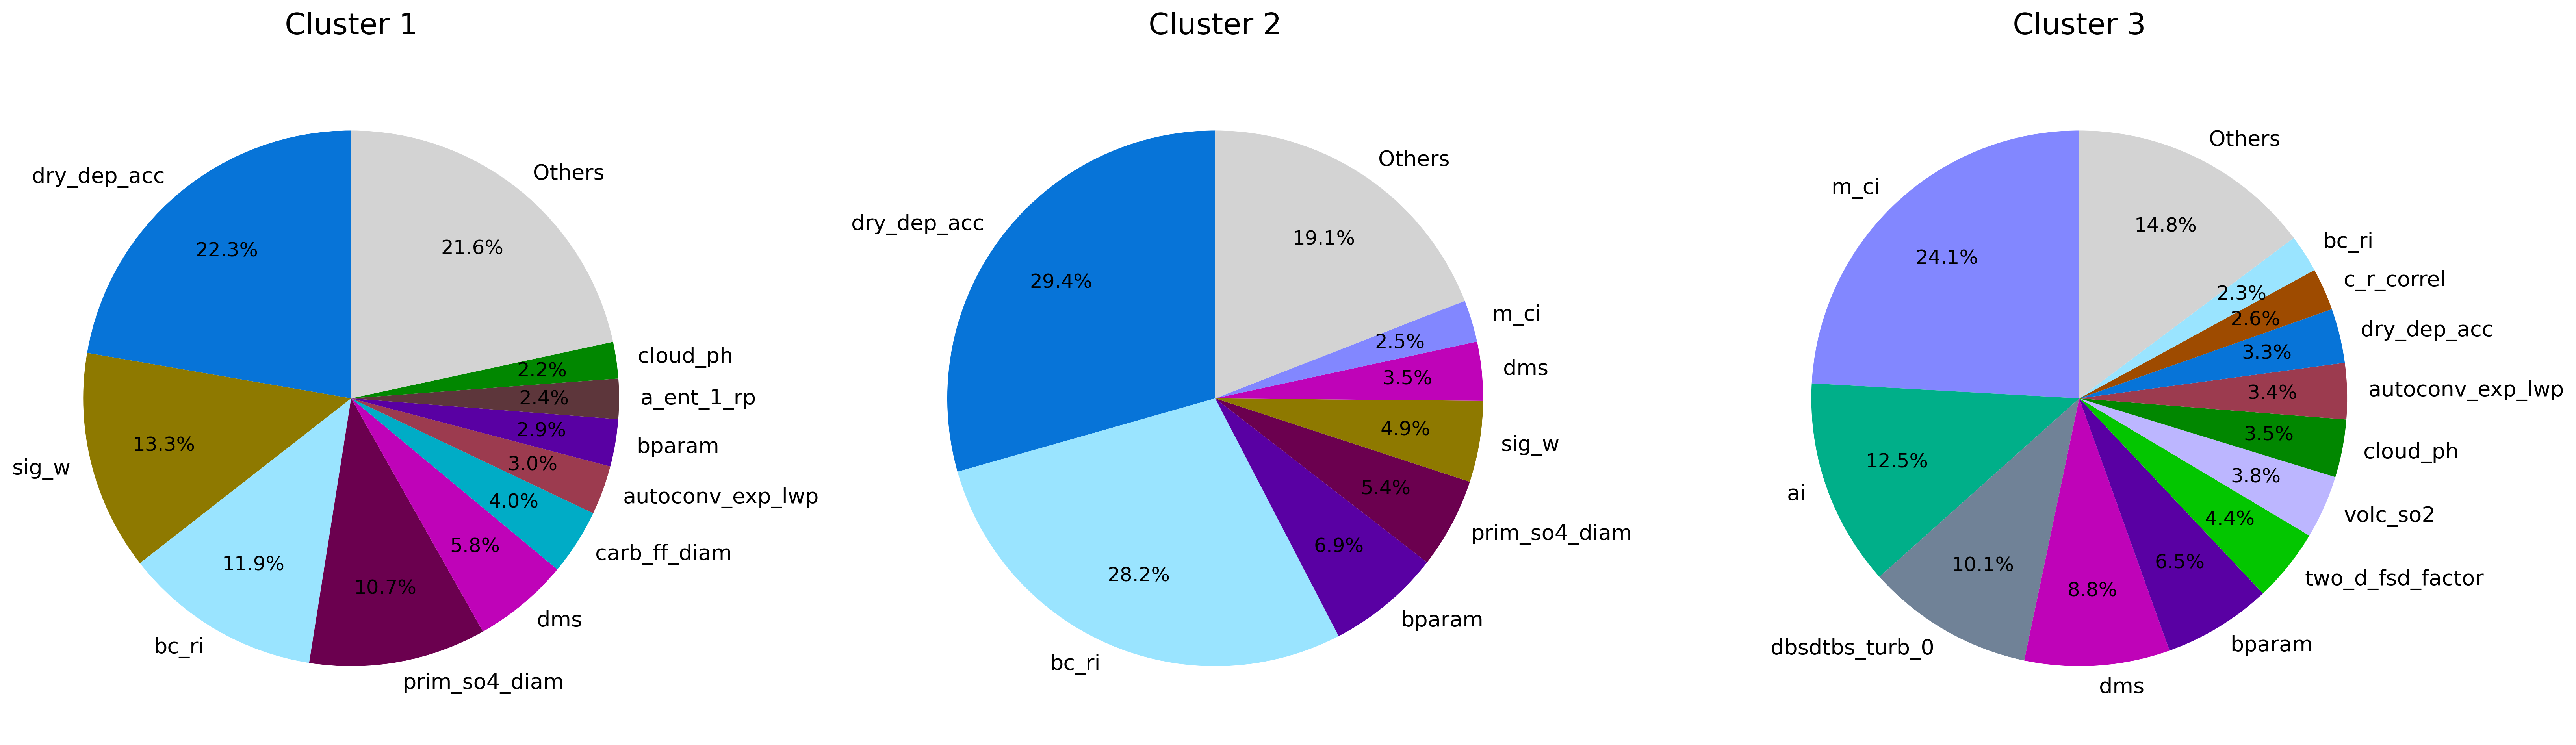

In [19]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import colorcet as cc

# ==========================================
# CONFIGURATION
# ==========================================
infile = "/gws/ssde/j25a/acure/jianxing/aci/GAM_values/ACI/cluster_ann_summary/ACI_ann_cluster_mean_contribution_optimal_constrained.csv"

target_clusters = ["c1", "c5", "c7"]

# Threshold for individual parameter contributions
contribution_threshold = 2.0

# Cluster display names
cluster_name_map = {
    "c1": "Cluster 1",
    "c5": "Cluster 2",
    "c7": "Cluster 3"
}

# ==========================================
# PARAMETER COLORS
# ==========================================
parameter_names_subset = [
    "bl_nuc",
    "ait_width",
    "cloud_ph",
    "carb_ff_diam",
    "carb_bb_diam",
    "carb_res_diam",
    "prim_so4_diam",
    "sea_spray",
    "anth_so2_chi",
    "anth_so2_asi",
    "anth_so2_eur",
    "anth_so2_nam",
    "anth_so2_r",
    "volc_so2",
    "bvoc_soa",
    "dms",
    "prim_moc",
    "dry_dep_ait",
    "dry_dep_acc",
    "dry_dep_so2",
    "kappa_oc",
    "sig_w",
    "rain_frac",
    "cloud_ice_thresh",
    "conv_plume_scav",
    "bc_ri",
    "oxidants_oh",
    "oxidants_o3",
    "bparam",
    "two_d_fsd_factor",
    "c_r_correl",
    "autoconv_exp_lwp",
    "autoconv_exp_nd",
    "dbsdtbs_turb_0",
    "ai",
    "m_ci",
    "a_ent_1_rp"
]

color_list = cc.glasbey[:len(parameter_names_subset)]
param_color_dict = dict(zip(parameter_names_subset, color_list))

PRINT_MISSING_WARNINGS = False

# Color assigned to the Others category
others_color = "#d3d3d3"

# ==========================================
# FONT SETTINGS
# ==========================================
title_fontsize = 18
label_fontsize = 13
percentage_fontsize = 12

# ==========================================
# READ DATA
# ==========================================
if not os.path.exists(infile):
    raise FileNotFoundError(f"Input file not found: {infile}")

df = pd.read_csv(infile)

required_cols = ["cluster", "param", "cluster_pct"]
missing_cols = [c for c in required_cols if c not in df.columns]

if missing_cols:
    raise ValueError(
        f"Missing required columns in input file: {missing_cols}"
    )

# ==========================================
# PLOT PIE CHARTS
# ==========================================
fig, axes = plt.subplots(
    1,
    len(target_clusters),
    figsize=(22, 8),
    dpi=300
)

if len(target_clusters) == 1:
    axes = [axes]

for ax, cluster in zip(axes, target_clusters):

    sub = df[df["cluster"] == cluster].copy()

    if sub.empty:
        ax.set_title(
            f"{cluster_name_map.get(cluster, cluster)} (no data)",
            fontsize=title_fontsize
        )
        ax.axis("off")
        continue

    # Sort parameters by contribution in descending order
    sub = sub.sort_values(
        "cluster_pct",
        ascending=False
    ).reset_index(drop=True)

    # Select parameters with contributions strictly greater than 2%
    top = sub[
        sub["cluster_pct"] > contribution_threshold
    ].copy()

    # Combine contributions less than or equal to 2% into Others
    others = sub[
        sub["cluster_pct"] <= contribution_threshold
    ].copy()

    others_sum = others["cluster_pct"].sum()

    if others_sum > 0:
        top = pd.concat(
            [
                top,
                pd.DataFrame(
                    [
                        {
                            "cluster": cluster,
                            "param": "Others",
                            "cluster_pct": others_sum
                        }
                    ]
                )
            ],
            ignore_index=True
        )

    labels = top["param"].tolist()
    sizes = top["cluster_pct"].tolist()

    # Assign a consistent color to each parameter
    colors = []

    for param in labels:

        if param == "Others":
            colors.append(others_color)

        elif param in param_color_dict:
            colors.append(param_color_dict[param])

        else:
            # Use grey for parameters not in the predefined list
            colors.append("#808080")

            if PRINT_MISSING_WARNINGS:
                print(
                    f"Warning: parameter '{param}' "
                    f"is missing from param_color_dict."
                )

    wedges, label_texts, percentage_texts = ax.pie(
        sizes,
        labels=labels,
        colors=colors,
        autopct="%1.1f%%",
        startangle=90,
        labeldistance=1.08,
        pctdistance=0.72,
        radius=1.0,
        textprops={
            "fontsize": label_fontsize
        }
    )

    # Adjust percentage-label font size separately
    for text in percentage_texts:
        text.set_fontsize(percentage_fontsize)

    ax.set_title(
        cluster_name_map.get(cluster, cluster),
        fontsize=title_fontsize,
        pad=18
    )

plt.tight_layout(
    w_pad=0.8
)

plt.show()